# Plot changes to unit selection between scenarios

In the 10 minute bias Taunton and Worcester maps, some LSOA appear in the Taunton and Worcester catchment areas when those units provide MT, even though in the "base" case their nearest unit offers MT.

This is because these LSOA are for example 6 minutes closer to Taunton than Bristol. When Taunton does not offer MT and there is a 10 minute MT unit bias, Bristol is picked. When Taunton offers MT, the bias is irrelevant and the original nearest unit Taunton is picked again.

Prove this here by looking at LSOA-level results.

## Code setup

In [18]:
import os
import numpy as np
import pandas as pd
import geopandas
import matplotlib.pyplot as plt
import cmasher as cmr  # for more colour maps

In [2]:
dir_data = os.path.join('..', 'data')
dir_output = os.path.join('..', 'output')
# Scenario results:
file_mt_bias15 = 'lsoa_change_unit_mt_availability_bias15min.csv'
file_bias15 = 'lsoa_change_unit_bias15min.csv'
# Geometry:
file_england_lsoa = 'Lower_layer_super_output_areas_(E+W)_2011_Boundaries_(Generalised_Clipped)_V2.zip'
file_uk_outlines = 'Countries_(December_2022)_GB_BFC.zip'
# Reference:
file_hospitals = 'stroke_hospitals_2025.csv'

## Load data

Load LSOA-level geography (unit selection and travel times) where the first unit attended changes when a new MT unit becomes available for travel bias of up to 15 minutes.

In [3]:
b = 'bias15min'
p = os.path.join('output', file_mt_bias15)
df_lsoa_mt_bias15 = pd.read_csv(p, index_col=0)

In [4]:
b = 'bias15min'
p = os.path.join('output', file_bias15)
df_lsoa_bias15 = pd.read_csv(p, index_col=0)

In [5]:
print(df_lsoa_mt_bias15.columns)

Index(['area_lower', 'Admissions_2025_Est', 'nearest_ivt_unit_base',
       'nearest_ivt_time_base', 'drip_ship_mt_travel_time_base',
       'nearest_ivt_unit_taunworc', 'nearest_ivt_time_taunworc',
       'drip_ship_mt_travel_time_taunworc', 'time_diff'],
      dtype='str')


## Load geometry

In [6]:
# Load the England and Wales LSOA shapefile
filename = os.path.join(dir_data, file_england_lsoa)
lsoa_gdf = geopandas.read_file(filename)

# Set or convert to British National Grid (EPSG:27700)
if lsoa_gdf.crs is None:
    lsoa_gdf = lsoa_gdf.set_crs("EPSG:27700")
else:
    lsoa_gdf = lsoa_gdf.to_crs("EPSG:27700")

In [7]:
# Get the England and Wales outline
filename = os.path.join(dir_data, file_uk_outlines)
countries_gdf = geopandas.read_file(filename)

# Set or convert to British National Grid (EPSG:27700)
if countries_gdf.crs is None:
    countries_gdf = countries_gdf.set_crs("EPSG:27700")
else:
    countries_gdf = countries_gdf.to_crs("EPSG:27700")

# Only keep England and Wales outlines:
mask = countries_gdf["CTRY22NM"].isin(["England", "Wales"])
countries_gdf = countries_gdf.loc[mask]
england = countries_gdf.boundary

In [8]:
# Load hospital coordinates from CSV and create a GeoDataFrame
p = os.path.join(dir_data, file_hospitals)
hospitals_df = pd.read_csv(p)

hospitals_gdf = geopandas.GeoDataFrame(
    hospitals_df,
    geometry=geopandas.points_from_xy(
        pd.to_numeric(hospitals_df["long"]),
        pd.to_numeric(hospitals_df["lat"]),
    ),
    crs="EPSG:4326",
).to_crs("EPSG:27700")

# Only keep hospitals in England:
hospitals_gdf = hospitals_gdf.loc[hospitals_gdf["Country"] == "England"]
display(hospitals_gdf.head(3))

,SSNAP name,Postcode,Country,SSNAP Region,Easting,Northing,long,lat,Hospital_City,LSOA11CD,Use_IVT,Use_MT,geometry
0,John Radcliffe Hospital,OX39DU,England,"Buckinghamshire, Oxford and Berkshire",453940,207531,-1.219806,51.763871,Oxford,E01028534,1,1,POINT (453940.001 207531)
1,Royal Berkshire Hospital,RG15AN,England,"Buckinghamshire, Oxford and Berkshire",472411,172962,-0.959330,51.451022,Reading,E01016414,1,0,POINT (472411.001 172961.999)
2,Wycombe General Hospital,HP112TT,England,"Buckinghamshire, Oxford and Berkshire",486386,192694,-0.753428,51.626442,High Wycombe,E01017839,1,0,POINT (486386.001 192694)


### Combine geography and affected LSOA

In [9]:
data = lsoa_gdf.copy()

rename_dict = dict([(c, f'{c}_mt_{b}') for c in df_lsoa_mt_bias15.columns])
data = pd.merge(
    data,
    df_lsoa_mt_bias15.rename(columns=rename_dict),
    left_on='LSOA11NM', right_on=f'area_lower_mt_{b}', how='left'
).drop(f'area_lower_mt_{b}', axis='columns')

rename_dict = dict([(c, f'{c}_{b}') for c in df_lsoa_bias15.columns])
data = pd.merge(
    data,
    df_lsoa_bias15.rename(columns=rename_dict),
    left_on='LSOA11NM', right_on=f'area_lower_{b}', how='left'
).drop(f'area_lower_{b}', axis='columns')

In [10]:
print(data.columns)

Index(['LSOA11CD', 'LSOA11NM', 'LSOA11NMW', 'geometry',
       'Admissions_2025_Est_mt_bias15min',
       'nearest_ivt_unit_base_mt_bias15min',
       'nearest_ivt_time_base_mt_bias15min',
       'drip_ship_mt_travel_time_base_mt_bias15min',
       'nearest_ivt_unit_taunworc_mt_bias15min',
       'nearest_ivt_time_taunworc_mt_bias15min',
       'drip_ship_mt_travel_time_taunworc_mt_bias15min',
       'time_diff_mt_bias15min', 'Admissions_2025_Est_bias15min',
       'nearest_ivt_unit_base_bias15min', 'nearest_ivt_time_base_bias15min',
       'drip_ship_mt_travel_time_base_bias15min',
       'nearest_ivt_unit_taunworc_bias15min',
       'nearest_ivt_time_taunworc_bias15min',
       'drip_ship_mt_travel_time_taunworc_bias15min', 'time_diff_bias15min'],
      dtype='str')


In [15]:
cols_time_diff = ['time_diff_bias15min', 'time_diff_mt_bias15min']
vmin = data[cols_time_diff].min(axis=None)
vmax = data[cols_time_diff].max(axis=None)

print(vmin, vmax)
cmax = max([vmax, abs(vmin)])

-15.0 15.0


### Plot affected LSOA

Set up colour scheme:

In [20]:
times = np.arange(-cmax, cmax+1, 1).astype(int)
colours = plt.get_cmap('cmr.prinsenvlag')(np.linspace(0.0, 1.0, len(times)))

dict_colours = dict(zip(times, colours))

Plot:

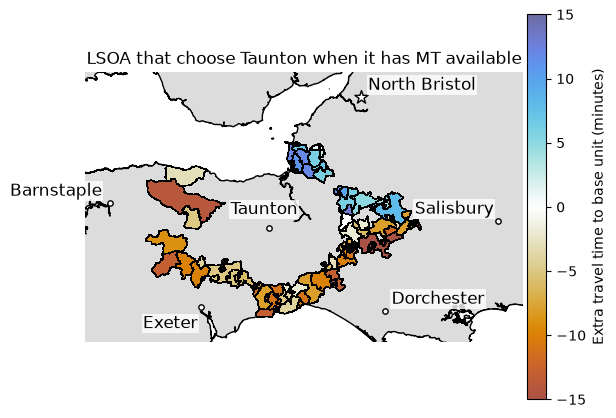

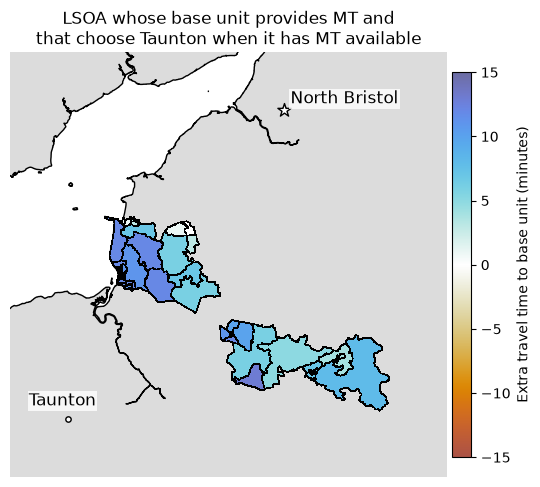

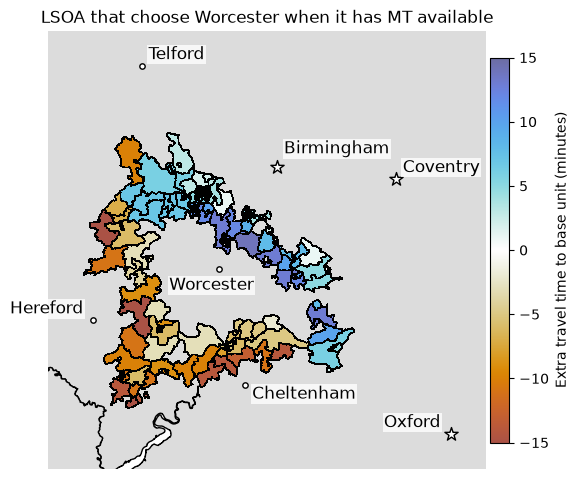

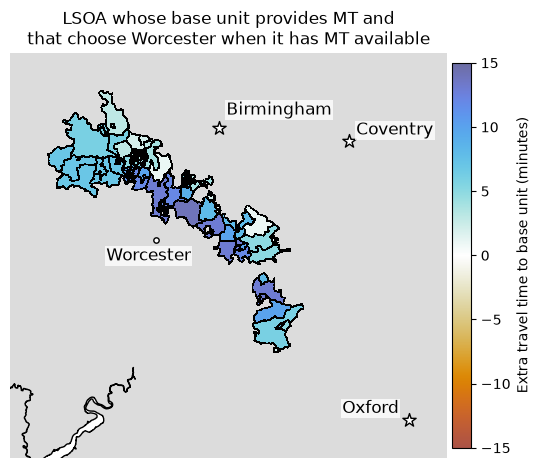

In [27]:
postcodes_taunworc = {'TA15DA': 'Taunton', 'WR51DD': 'Worcester'}
dict_cols = {
    f'time_diff_{b}': {
        'title': '',
        'savename': '',
    },
    f'time_diff_mt_{b}': {
        'title': 'whose base unit provides MT and\n',
        'savename': '_mt',
    }
}
for unit_taunworc, label_taunworc in postcodes_taunworc.items():
    for col, col_label_dict in dict_cols.items():
    
        data_here = data[data[col].notna()]
        data_here[col] = data_here[col].convert_dtypes()
        data_here = data_here[data_here[f'nearest_ivt_unit_taunworc_{b}'] == unit_taunworc]
        cols_units = [f'nearest_ivt_unit_base_{b}',
                      f'nearest_ivt_unit_taunworc_{b}']
        units_here = np.unique(
            data_here.loc[data_here[cols_units].notna().any(axis='columns'), cols_units]
            .values.flatten()
        )
        hospitals_gdf_here = hospitals_gdf[hospitals_gdf['Postcode'].isin(units_here)]
        
        bounds_l = data_here.total_bounds
        bounds_h = hospitals_gdf_here['geometry'].total_bounds
        buffer = 10000  # metres
        bounds = (
            min(bounds_l[0], bounds_h[0]) - buffer,
            min(bounds_l[1], bounds_h[1]) - buffer,
            max(bounds_l[2], bounds_h[2]) + buffer,
            max(bounds_l[3], bounds_h[3]) + buffer,
        )
        
        fig, ax = plt.subplots(figsize=(6, 10))
        
        # Country borders:
        england.plot(ax=ax, edgecolor='k', facecolor='gainsboro', linewidth=1, zorder=0)
        
        # # LSOA:
        # for time, df_here in data_here.groupby(col):
        #     df_here.plot(
        #         ax=ax,
        #         label=time,
        #         color=dict_colours[time],
        #         edgecolor='k',
        #         linewidth=0.5,
        #     )
        # ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',
        #           title='Extra travel time\nto base unit\n(minutes)')
        # Plot LSOA:
        data_here.plot(
            column=col,
            ax=ax,
            cmap=plt.get_cmap('cmr.prinsenvlag'),
            vmin=-cmax,
            vmax=cmax,
            # missing_kwds={'color': 'lightgrey'},
            antialiased=False,
            linewidth=0.5,
            edgecolor='k',
            legend=True,
            legend_kwds=dict(
                shrink=0.5,      # shrink the colorbar to 50% of its original size
                pad=0.01,        # gap between map and colorbar (default 0.05)
                fraction=0.05,   # width of colorbar relative to the axes
                label='Extra travel time to base unit (minutes)'
            ),
            # cax=cax,
        )
        
        # Stroke units:
        ivt_mask = pd.to_numeric(
            hospitals_gdf_here['Use_IVT'], errors='coerce').eq(1)
        mt_mask = pd.to_numeric(
            hospitals_gdf_here['Use_MT'], errors='coerce').eq(1)
        
        hospitals_gdf_here.loc[ivt_mask].plot(
            ax=ax, edgecolor='k', facecolor='w', markersize=15, marker='o',
            zorder=99
        )
        hospitals_gdf_here.loc[mt_mask].plot(
            ax=ax, edgecolor='k', facecolor='w', markersize=100, marker='*',
            zorder=99
        )
    
        for _, hospital in hospitals_gdf_here.iterrows():
            if hospital["Hospital_City"] in ['Worcester']:
                label_offset = (-36, -15)
            elif hospital["Hospital_City"] in ['Birmingham']:
                label_offset = (5, 10)
            elif hospital["Hospital_City"] in ['Barnstaple']:
                label_offset = (-72, 5)
            elif hospital["Hospital_City"] in ['Salisbury']:
                label_offset = (-60, 5)
            elif hospital["Hospital_City"] in ['Oxford']:
                label_offset = (-48, 5)
            elif hospital["Hospital_City"] in ['Taunton']:
                label_offset = (-28, 10)
            elif hospital["Hospital_City"] in ['Hereford']:
                label_offset = (-60, 5)
            elif hospital["Hospital_City"] in ['Exeter']:
                label_offset = (-42, -15)
            elif hospital["Hospital_City"] in ['Cheltenham']:
                label_offset = (5, -10)
            else:
                label_offset = (5, 5)
                
            ax.annotate(
                hospital["Hospital_City"],
                xy=(hospital.geometry.x, hospital.geometry.y),
                xytext=label_offset,
                textcoords="offset points",
                fontsize=12,
                color='black',
                zorder=100,
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.8,
                    "pad": 1,
                },
            )
        
        ax.set_xlim(bounds[0], bounds[2])
        ax.set_ylim(bounds[1], bounds[3])
    
        title = f'LSOA {col_label_dict["title"]}that choose {label_taunworc} when it has MT available'
        ax.set_title(title)
        
        # Remove ticks:
        ax.set_axis_off()
    
        savename = f'map_lsoa_change_nearest_unit{col_label_dict["savename"]}_{label_taunworc}.png'
        p = os.path.join('images', savename)
        plt.savefig(p, bbox_inches='tight', dpi=300)
        plt.show()

Blue LSOA (positive extra travel times) will go to an MT unit in the base scenario if it is not more than X minutes farther away than Taunton or Worcester.

Orange LSOA (negative extra travel times) will go to their nearest unit in the base scenario and to Taunton or Worcester if they gain MT and they are not more than X minutes farther away.